# K-Means Clustering - Part 1: Generate and Visualize Data

The main idea is to generate data, visualize it, and let K-Means discover groups **without using the existing labels**.

## 1. Generate a dataset

We use `make_blobs()` from Scikit-learn to generate 500 data points with two features.

In [179]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import numpy as np

X, y = make_blobs(
    n_samples=500,
    n_features=2,
    centers=5,
    random_state=42
)

### What do these parameters mean?

| Parameter | Meaning |
|---|---|
| `n_samples=500` | Generate 500 data points |
| `n_features=2` | Each point has two features |
| `centers=5` | Generate data around five centers |
| `random_state=42` | Make the generated dataset reproducible |

The resulting shapes are:

In [180]:
print(X.shape)  # (500, 2)
print(y.shape)  # (500,)

(500, 2)
(500,)


- `X` contains the feature values.
- `y` contains the original group labels generated by `make_blobs()`.

## 2. Why don't we use `y`?

K-Means is an **unsupervised** learning algorithm, so it discovers clusters from `X` without needing the correct labels.

In this lecture, `y` is kept only so you can compare the discovered clusters with the original groups later.

> Think of it like receiving 500 customer records without knowing which customer group each person belongs to. K-Means tries to discover those groups on its own.

## 3. Visualize the data

Because each point has only two features, we can plot it on a 2D graph.

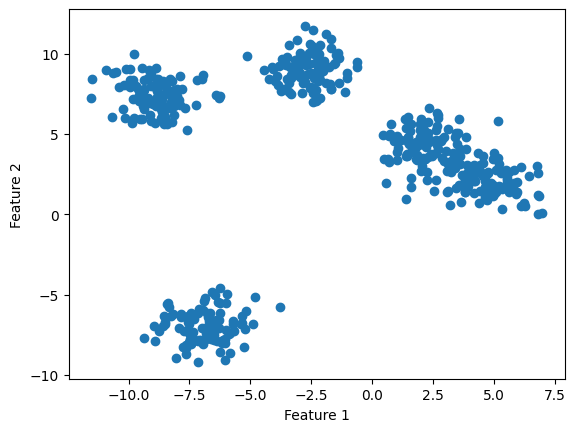

In [181]:
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Here:

- `X[:, 0]` selects all rows from the first column (Feature 1), plotted on the x-axis.
- `X[:, 1]` selects all rows from the second column (Feature 2), plotted on the y-axis.

# K-Means Implementation - Part 2: Initializing Centroids

In this lecture, we implement the first step of K-Means: **randomly initializing the centroids**.

Let's understand it using the pizza-shop example.

## 1. Real-life example: Where should we open pizza shops?

Imagine 500 customers live in different locations across a city. You want to open 3 pizza shops so that customers are, on average, close to a shop.

- Each **customer** is a data point with coordinates $(x, y)$.
- Each **pizza shop** is a centroid.
- $K = 3$ means we want 3 clusters and 3 shop locations.

K-Means tries to place the shops to **minimize the total squared distance** between each customer and their nearest shop.

## 2. Normalize the dataset

The lecture first standardizes the features:

$$
x' = \frac{x - \mu}{\sigma}
$$

Where:

- $x$ = original feature value.
- $\mu$ = mean of that feature.
- $\sigma$ = standard deviation.
- $x'$ = standardized value.

This gives the features a comparable scale, which is important when distances are used.

In [182]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

X, y = make_blobs(
    n_samples=500,
    n_features=2,
    centers=5,
    random_state=42
)

scaler = StandardScaler()
X = scaler.fit_transform(X)

Here, `y` is not used by K-Means; it is available only for comparison with the original generated groups.

## 3. Randomly initialize K centroids

The lecture chooses $K = 5$ and generates random coordinates for each centroid.

In [183]:
import numpy as np

K = 5
num_features = X.shape[1]

for i in range(K):
    center = 2 * np.random.random(num_features) - 1
    center = center * K
    print(center)

[ 1.64008444 -3.26538913]
[-4.64023401 -0.18910468]
[-4.46438908  1.50903354]
[3.55363041 1.09556553]
[2.90303262 2.70734194]


### Breaking down the random initialization formula

```python
np.random.random(num_features)
```

Generates random numbers between 0 and 1. Since there are two features, it generates two coordinates.

```python
2 * np.random.random(num_features) - 1
```

Transforms the numbers to the range $[-1, 1)$.

```python
center = center * K
```

Scales them to approximately $[-K, K)$.

For example, if $K = 5$, the generated coordinates fall approximately between $-5$ and $5$.

The purpose is to initialize the centroids within a reasonable region rather than far away from the data.

> **Note:** The lecture's initialization range is a teaching choice. In production implementations, K-Means commonly initializes centroids using data points or the **K-Means++** method.

## 4. Store each centroid in a dictionary

The lecture stores three things about every centroid:

- `center`: its coordinates.
- `color`: its display color.
- `points`: the data points assigned to it.

In [184]:
k=5
colors = ["green", "red", "blue", "yellow", "orange"]

centroids = {}

for i in range(K):
    center = 2 * np.random.random(num_features) - 1
    center = center * K

    centroids[i] = {
        "center": center,
        "color": colors[i],
        "points": []
    }

The dictionary will have a structure like this:

```python
{
    0: {
        "center": [1.2, -2.3],
        "color": "green",
        "points": []
    },
    1: {
        "center": [-3.1, 0.8],
        "color": "red",
        "points": []
    }
}
```

These coordinates and colors are just examples; your actual coordinates will be randomly generated.

The `points` list is initially empty because the algorithm has not assigned any data points yet.

# K-Means Implementation - Part 3: Step 2A - Assign Points to Clusters

In this lecture, we learn how K-Means assigns every data point to its **nearest centroid**.

Imagine you have 500 customers and 5 pizza shops. Each customer should be assigned to the nearest shop.

## 1. Calculate the distance

The lecture uses **Euclidean distance**:

$$
d(P, Q) = \sqrt{\sum_{j=1}^{n} (P_j - Q_j)^2}
$$

For example, customer $P = (5, 3)$ and pizza shop $Q = (2, 7)$:

$$
d = \sqrt{(5-2)^2 + (3-7)^2} = \sqrt{9 + 16} = 5
$$

In [185]:
def distance(p, q):
    return np.sqrt(np.sum((p - q) ** 2))

print(distance(np.array([5, 3]), np.array([2, 7])))  # 5.0

5.0


- `p - q`: subtract corresponding features.
- `** 2`: square each difference.
- `np.sum()`: add the squared differences.
- `np.sqrt()`: take the square root.

## 2. Find the nearest centroid

Suppose a customer has these distances from three pizza shops:

| Shop | Distance |
|---|---|
| Shop 0 | 5 |
| Shop 1 | 8 |
| Shop 2 | 12 |

The nearest shop is **Shop 0** because its distance is smallest.

In [186]:
distances = [5, 8, 12]
cluster_id = np.argmin(distances)
print(cluster_id)  # 0

0


`np.argmin()` returns the **index** of the smallest value. Here, it returns `0`.

## 3. Assign every point to a cluster

The lecture's function follows this logic:

In [187]:
def assignPtsToCluster(X, centroids):
    m = X.shape[0]
    k = len(centroids)

    for i in range(m):
        current_point = X[i]
        distances = []

        for cluster_id in range(k):
            d = distance(centroids[cluster_id]["center"], current_point)
            distances.append(d)

        nearest_cluster = np.argmin(distances)
        centroids[nearest_cluster]["points"].append(current_point)

### How does it work?

1. Loop through all data points in `X`.
2. Calculate each point's distance from every centroid.
3. Find the nearest centroid using `np.argmin()`.
4. Append the point to that centroid's `points` list.

This is called **hard clustering** because each point is assigned to exactly one cluster.

> **Important:** Before running this assignment step again, clear each centroid's previous `points` list. Otherwise, points from earlier iterations will remain in the lists.

In [188]:
# Clear old assignments, then assign points
for cluster_id in range(K):
    centroids[cluster_id]["points"] = []

assignPtsToCluster(X, centroids)

for cluster_id in range(K):
    print(cluster_id, centroids[cluster_id]["color"], len(centroids[cluster_id]["points"]))

0 green 87
1 red 0
2 blue 399
3 yellow 14
4 orange 0


## 4. Visualize the assignment

Initially, the centroids are random. After assignment:

- Points near the red centroid go into the red cluster.
- Points near the blue centroid go into the blue cluster.
- Points near the yellow centroid go into the yellow cluster.

The same process applies to every centroid.

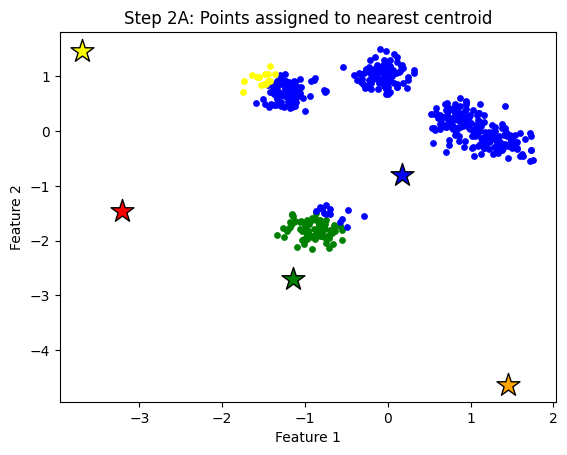

In [189]:
import matplotlib.pyplot as plt

for cluster_id in range(K):
    pts = np.array(centroids[cluster_id]["points"])
    color = centroids[cluster_id]["color"]
    if len(pts) > 0:
        plt.scatter(pts[:, 0], pts[:, 1], c=color, s=15)
    center = centroids[cluster_id]["center"]
    plt.scatter(center[0], center[1], c=color, marker="*", s=300, edgecolors="black")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Step 2A: Points assigned to nearest centroid")
plt.show()

A centroid with no points simply means no data point was closer to it than to another centroid. This can happen with random initialization.

## 5. Remember the algorithm

- **Step 1:** Initialize centroids randomly.
- **Step 2A:** Assign each point to its nearest centroid.
- **Step 2B:** Recalculate each centroid using the mean of its assigned points.
- Repeat Steps 2A and 2B until the clusters stabilize.

> **Key idea:** `distance()` measures closeness, `np.argmin()` finds the nearest centroid, and `append()` stores the point in that cluster.

In [190]:
# Step 2b
def updateClusters(centroids):
    # Update every centroid by taking the mean of points assigned to the cluster
    for kx in range(k):
        pts = np.array(centroids[kx]['points'])

        # If a cluster has non-zero points
        if pts.shape[0] > 0:
            newCenter = pts.mean(axis=0)
            centroids[kx]['center'] = newCenter

        centroids[kx]['points'] = []  # Clear the list for Step 2a

In [191]:
def plotClusters(centroids):
    for kx in range(k):
        pts = np.array(centroids[kx]['points'])

        # Plot the points
        if pts.shape[0] > 0:
            plt.scatter(
                pts[:, 0],
                pts[:, 1],
                color=centroids[kx]['color']
            )

        # Plot the cluster center (centroid)
        uk = centroids[kx]['center']
        plt.scatter(
            uk[0],
            uk[1],
            color="black",
            #centroids[kx]['color'],
            marker='*'
        )

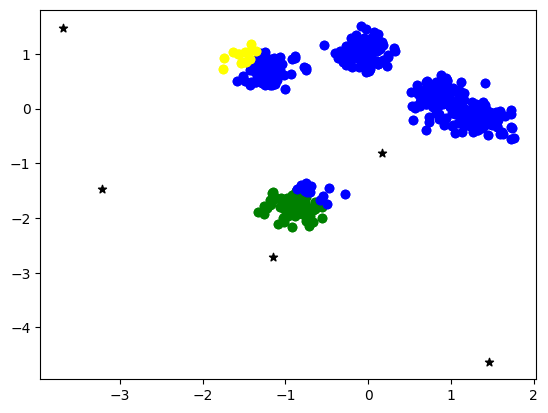

In [192]:
assignPtsToCluster(X, centroids)
plotClusters(centroids)
updateClusters(centroids)

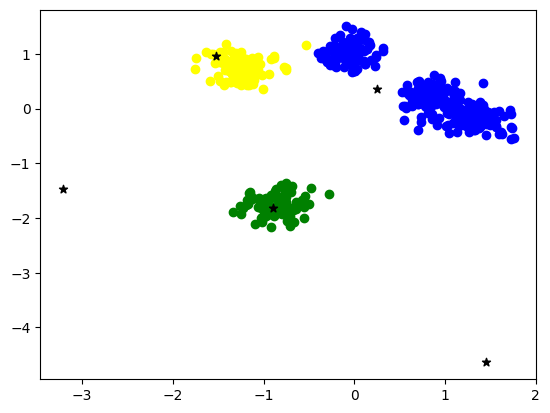

In [193]:
assignPtsToCluster(X, centroids)
plotClusters(centroids)
updateClusters(centroids)

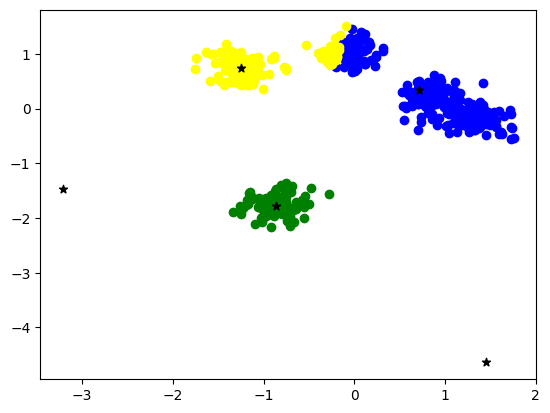

In [194]:
assignPtsToCluster(X, centroids)
plotClusters(centroids)
updateClusters(centroids)

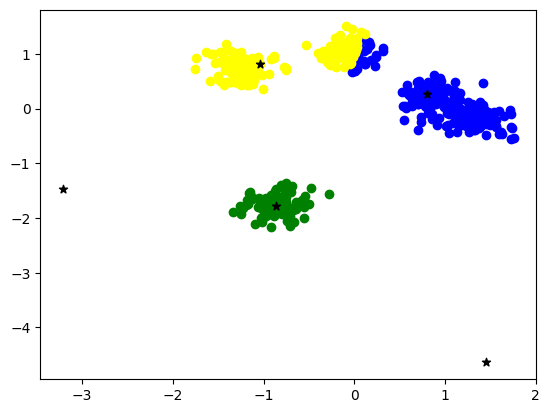

In [195]:
assignPtsToCluster(X, centroids)
plotClusters(centroids)
updateClusters(centroids)